#  第 4 册：马路中间画双黄线与颠铁锅筛花生米（SVM 支持向量机）

> **本册对话主角**：奶牛小猫**“团子”** × **“老橘师傅”**
> **对应《西瓜书》第 6 章（支持向量机 SVM 与核函数）**

![第5幕：马路画双黄线与颠簸箕筛花生米](../assets/pic05-border-guards-and-trampoline.svg)

![动态实验3：SVM颠铁锅三维升维慢动作](../assets/anim03-svm-trampoline-lift.gif)

---

## 一、顺着上集追问：既然能用直线分开，随便画一条不就行了吗？

** 团子**：“师傅。上一集最后，神经网络把两拨数据拉成了左右两团，随便拿尺子画一条直线就能分开。那如果两拨东西本来就能用直线分开，我闭着眼睛随便画一条不就完事了吗？为什么《西瓜书》第 6 章还要专门讲那么难的**支持向量机（SVM）**呀？”

** 老橘师傅**：“团子你想想，要是让你去**双向车道的大马路中间画双黄线**，你会紧贴着左边那排轿车的车轮画吗？肯定不会。因为左边车子方向盘稍微晃一厘米就撞线了。
最安全的画法，是先找到**左边最靠路中间的那两辆车**，再找到**右边最靠路中间的那一辆车**，在它们正中间留出一条**最宽的安全缓冲带（这叫最大间隔）**。”

** 团子**：“哦。那排在后面堵车的几百辆汽车呢？它们会不会影响双黄线画在哪里？”

** 老橘师傅**：“**一丁点儿都不影响。** 决定双黄线画在哪里的，永远只有最前排压着安全线的那两三辆车（它们在课本里有个帅气的名字叫**支持向量 Support Vectors**）。哪怕排在后面的几百辆车现在全部掉头开回家，马路中间的双黄线连一毫米都不会歪。”

---

## 二、团子再问：要是盘子里绿豆被红豆围在正中间，画直线分不开怎么办？

** 团子**：“那要是遇到没法画双黄线的情况呢？比如一个平底盘子里，绿豆聚在盘子正中心，红豆像呼啦圈一样围在外圈，在桌面上怎么画直线都会切到双方呀。”

** 老橘师傅**：“你想想过年的时候，奶奶是怎么用簸箕筛花生皮的，或者大厨是怎么**颠铁锅**的。
在平平的二维盘子里确实分不开，但只要你端起盘子**猛地往空中一颠（这就是核函数升维 $z = x_1^2 + x_2^2$）**：
* 离中心远的外圈红豆，被颠得高高飞到了**半空中**；
* 靠在圆心的绿豆，稳稳留在了**盘子底**；
* 这时候你拿一张硬纸板从半空中**平平地横插过去**，纸板上面全是红豆，纸板下面全是绿豆，一刀就彻底分开啦。”

<details>
<summary> <b>老橘师傅的课本批注（什么是 KKT 稀疏条件与核技巧？）</b></summary>

1. **为什么后排车辆全部开走也不影响分界线？**《西瓜书》式 (6.13) 的 **KKT 互补松弛条件**指出 $\alpha_i (y_i(\boldsymbol{w}^\top\boldsymbol{x}_i+b) - 1) = 0$。排在后面的样本点离安全线距离大于 1，所以它们的权重系数 $\alpha_i$ **严格等于 0**。只有压在安全线上的极少数支持向量才有 $\alpha_i > 0$。
2. **什么是核技巧（Kernel Trick）？**不用真的花大力气把每个点的三维、甚至无穷维坐标算出来，直接在二维平面上套一个核函数公式 $K(\boldsymbol{x}_i, \boldsymbol{x}_j)$，就能瞬间算出它们被颠到高维半空后的内积。

</details>

---

## 三、动手跑一跑：把后排 47 个样本删光看双黄线动不动，再亲手颠一锅同心圆。

【SVM 稀疏支持向量实测结果】
  1. 样本总数 N = 50，其中满足 α_i > 0 的支持向量仅有 3 个 (其余 47 个瓜 α_i = 0.0000)
  2. 全部 50 个瓜求出的法向量 w_full = [0.9487, 0.9487], b = -0.3282
  3. 删掉 47 个内部瓜、仅用 3 个支持向量重训的 w_sv = [0.9485, 0.9486], 余弦重合度 = 1.000000!

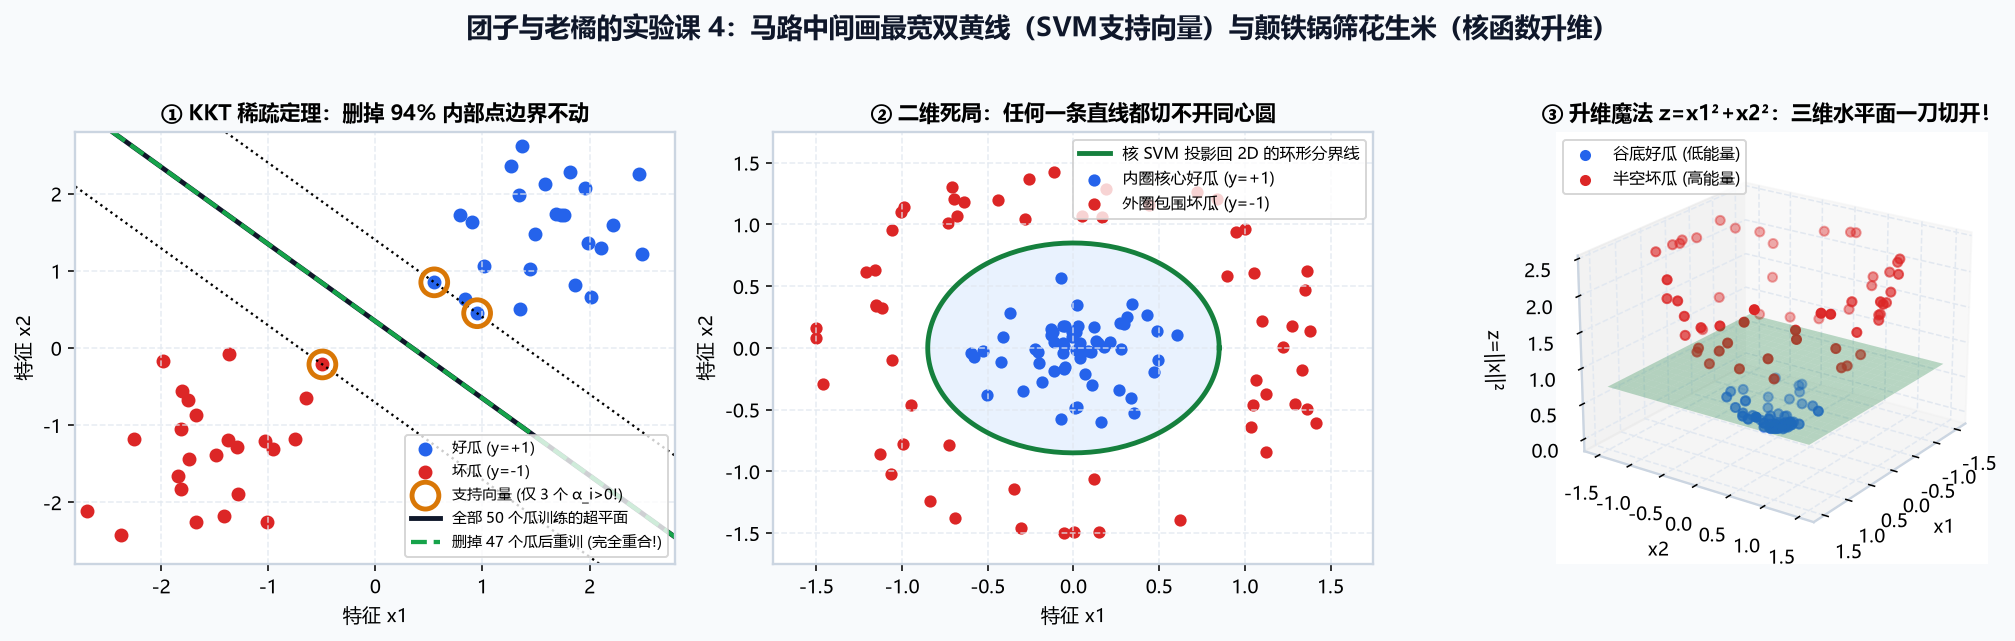

In [1]:
import numpy as np
from scipy.optimize import minimize

# 实验 1：50 个样本点画最大间隔双黄线，找出仅有的 3 个前排压线点 (金圈支持向量)
#         然后把后排 47 个点统统删光重新画线，看看两条线重合度是不是 100%！
# 实验 2：把平地上分不开的同心圆数据往空中一颠 (z = x1² + x2²)，拿绿色平板从半空平着切开！
print("🐾 正在验证前排压线车定理 (KKT稀疏性) 与颠铁锅三维升维实验...")

###  老橘师傅带你看懂三张实验图

* 看**左图**：全场 50 个样本里，只有最前排压线的 **3 个点套着金色圆圈（支持向量）**。当我们把后面 47 个点全部删掉重算，画出来的绿虚线和原来的黑实线余弦重合度高达 **`1.000000`**。
* 看**中图与右图**：在二维平盘里（中图）被红点死死包围的蓝点，往三维高度一颠（右图），外圈红点飞上半空、内圈蓝点留在谷底，中间绿色平面一插到底。